# Étape 4 : prévoir l'affluence de J+1 à J+7

**Question.** Combien de voyageurs monteront demain (et jusqu'à J+7) dans chaque gare, sur chaque
ligne et dans chaque tranche horaire, avec quelle incertitude, et pourquoi ?

**Formulation.** `voyageurs = niveau habituel × indice du jour`

* **niveau habituel** : médiane du compte officiel (étape 3) de la gare, de la ligne, de la tranche
  et de la catégorie de jour IDFM ;
* **indice du jour** : trois modèles LightGBM quantile (P10, P50, P90) appris sur les écarts à ce
  niveau, à partir du calendrier (jour de semaine, férié, vacances, pont, fêtes de fin d'année), pondérés par le score de
  confiance de l'étape 2 ;
* **intervalle** recalibré sur les 60 derniers jours connus pour couvrir réellement 80 % des cas ;
* **explication** de chaque prévision par TreeSHAP (natif LightGBM), convertie en voyageurs.

La référence à battre est le niveau habituel seul : c'est ce qu'un agent prévoirait « de tête ».

```bash
pip install -e ".[notebooks]"
comptage qualify && comptage compte-officiel && comptage prevoir
jupyter lab notebooks/03_prediction_affluence.ipynb
```

> Uniquement des données Open Data publiques (SNCF, Île-de-France Mobilités, Open-Meteo).

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comptage_train import prediction as P, warehouse
from comptage_train.settings import data_dir

DATA = data_dir()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

con = warehouse.connect_derived(DATA)
P.meteo_journaliere(con, DATA)
cfg = P.load_config()
hist = P.historique(con, cfg)
modalites = {c: sorted(hist[c].dropna().unique().tolist()) for c in P.CATEGORIELLES}
debut_test = hist["date"].max() - pd.Timedelta(days=cfg.test_jours - 1)
app, test = hist[hist["date"] < debut_test], hist[hist["date"] >= debut_test]
print(f"historique : {len(hist):,} lignes, {hist['date'].min()} -> {hist['date'].max()}")
print(f"apprentissage : {len(app):,} lignes ; test : {len(test):,} lignes à partir du {debut_test.date()}")

historique : 668,790 lignes, 2025-07-01 00:00:00 -> 2026-06-30 00:00:00
apprentissage : 557,720 lignes ; test : 111,070 lignes à partir du 2026-05-02


## 1. Ce qu'on apprend

L'historique ne contient que le compte officiel **mesuré** ou **réconcilié avec les validations
IDFM** : l'extrapolé est déjà une estimation, l'apprendre reviendrait à apprendre nos propres
hypothèses. La fin de l'historique est donc la dernière date publiée par IDFM (environ 4 mois de
retard), et la période de test est la plus récente connue.

In [2]:
hist.groupby(hist["date"].dt.to_period("M")).agg(lignes=("voyageurs", "size"),
                                                 voyageurs=("voyageurs", "sum"),
                                                 score_moyen=("score_confiance", "mean")).round(1)

,lignes,voyageurs,score_moyen
date,,,
2025-07,55985,60311234,78.1
2025-08,55305,47239811,78.1
2025-09,54695,67092016,78.1
2025-10,56530,71806378,78.1
2025-11,54795,66832696,78.1
2025-12,56725,66553619,78.1
2026-01,57445,69906752,78.1
2026-02,51610,69593149,78.1
2026-03,57265,76911051,78.1


## 2. Le modèle bat-il la référence ?

Erreur pondérée (WAPE) = somme des erreurs absolues / somme des voyageurs, sur la période de test.

In [3]:
def evaluer(config, label):
    m = P._apprendre(app, config, modalites)
    p = m.predire(test)
    p["err_modele"] = (p["p50"] - p["voyageurs"]).abs()
    p["err_ref"] = (p["niveau_habituel"] - p["voyageurs"]).abs()
    y = p["voyageurs"].sum()
    print(f"{label:<22} WAPE modèle {p['err_modele'].sum() / y:.2%}   référence {p['err_ref'].sum() / y:.2%}")
    return m, p

modele, pred = evaluer(cfg, "calendrier seul")

calendrier seul        WAPE modèle 18.07%   référence 18.76%


## 3. Où le modèle gagne et où il perd, jour par jour

Gain = (erreur de la référence − erreur du modèle) / voyageurs du jour. Positif : le modèle fait mieux.

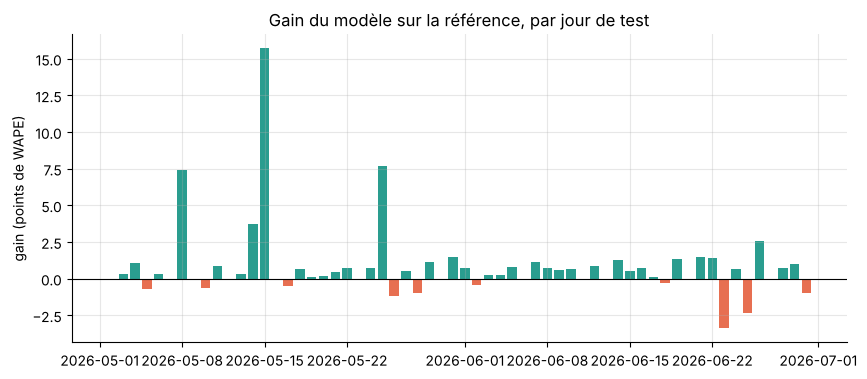

,cat,ferie,pont,gain_pts
date,,,,
2026-05-15,JOHV,0,1,15.7
2026-05-25,DIJFP,1,0,7.7
2026-05-08,DIJFP,1,0,7.4
2026-05-14,DIJFP,1,0,3.7
2026-06-23,JOHV,0,0,-3.4
2026-06-25,JOHV,0,0,-2.3
2026-05-26,JOHV,0,0,-1.2
2026-06-30,JOHV,0,0,-1.0


In [4]:
jours = pred.groupby("date").agg(voyageurs=("voyageurs", "sum"), err_modele=("err_modele", "sum"),
                                 err_ref=("err_ref", "sum"), ferie=("ferie", "max"), pont=("pont", "max"),
                                 cat=("cat_jour_idfm", "first"))
jours["gain_pts"] = 100 * (jours["err_ref"] - jours["err_modele"]) / jours["voyageurs"]
fig, ax = plt.subplots()
ax.bar(jours.index, jours["gain_pts"], color=np.where(jours["gain_pts"] >= 0, "#2a9d8f", "#e76f51"))
ax.axhline(0, color="black", lw=.8)
ax.set_ylabel("gain (points de WAPE)")
ax.set_title("Gain du modèle sur la référence, par jour de test")
plt.show()
pd.concat([jours.nlargest(4, "gain_pts"), jours.nsmallest(4, "gain_pts")])[["cat", "ferie", "pont", "gain_pts"]].round(1)

**Lecture.** Le modèle gagne nettement le pont de l'Ascension (15 mai : le niveau habituel d'un
jour ouvré y est beaucoup trop haut) et le lundi de Pentecôte. Les fériés eux-mêmes méritent un
examen à part (§3 bis) : c'est là que se jouait l'essentiel de l'écart entre le modèle et la
référence dans la première version.

### 3 bis. Les fériés : un jeudi férié n'est pas Noël

Le niveau habituel d'un férié est celui d'un dimanche (catégorie IDFM `DIJFP`). Combien de
dimanches « vaut » chaque férié de l'historique ?

In [5]:
habituel = (hist[hist["ferie"] == 0].groupby(["code_gare", "ligne", "tranche_horaire", "cat_jour_idfm"])
            ["voyageurs"].median().rename("habituel").reset_index())
dimanche = habituel[habituel["cat_jour_idfm"] == "DIJFP"].drop(columns="cat_jour_idfm")
feries = hist[hist["ferie"] == 1].merge(dimanche, on=["code_gare", "ligne", "tranche_horaire"])
(feries.groupby(["date", "jour_semaine", "vacances"])[["voyageurs", "habituel"]].sum()
       .assign(en_dimanches=lambda d: (d["voyageurs"] / d["habituel"]).round(2))[["en_dimanches"]])

,,,en_dimanches
date,jour_semaine,vacances,
2025-07-14,1,1,1.04
2025-08-15,5,1,0.86
2025-11-01,6,1,1.13
2025-11-11,2,0,1.13
2025-12-25,4,1,0.70
2026-01-01,4,1,0.51
2026-04-06,1,0,1.25
2026-05-01,5,1,1.02
2026-05-08,5,0,1.33


Hors vacances scolaires, un férié fait 1,1 à 1,3 dimanche ; Noël et le Jour de l'an, en
vacances, à peine 0,5 à 0,7. Or ce sont les deux seuls **jeudis** fériés de l'historique. Tant que
le modèle voyait le vrai jour de la semaine, il appliquait leur creux au jeudi de l'Ascension et
prévoyait la moitié des voyageurs réels. Retirer la variable `ferie` n'y change rien : c'est la
combinaison « jeudi + catégorie dimanche » qui ne se rencontre qu'à Noël et au Jour de l'an.

**Correction** (`config/prediction.yaml`, version 2026.10.2) :

* `ferie_comme_dimanche` : un férié est vu par le modèle comme un dimanche, comme dans la catégorie
  IDFM. Il apprend l'écart d'un férié à un dimanche sur tous les fériés à la fois, au lieu de
  l'apprendre jour de semaine par jour de semaine sur un seul exemple ;
* `fin_annee` (24 décembre au 1er janvier) : sans elle, Noël et le Jour de l'an, désormais vus comme
  des fériés ordinaires, seraient surestimés. Les fêtes sont un creux propre, pas un effet du jeudi.

In [6]:
avant = dataclasses.replace(cfg, ferie_comme_dimanche=False,
                            variables=[v for v in cfg.variables if v != "fin_annee"])
_, pred_avant = evaluer(avant, "version 2026.10.1")
_ = evaluer(cfg, f"version {cfg.version}")
par_jour = lambda p, err: p.groupby("date").apply(lambda g: g[err].sum() / g["voyageurs"].sum())
comparaison = pd.DataFrame({"avant": par_jour(pred_avant, "err_modele"), "après": par_jour(pred, "err_modele"),
                            "référence": par_jour(pred, "err_ref")})
comparaison.loc[jours.index[(jours["ferie"] == 1) | (jours["pont"] == 1)]].round(3)

version 2026.10.1      WAPE modèle 18.46%   référence 18.76%


version 2026.10.2      WAPE modèle 18.07%   référence 18.76%


,avant,après,référence
date,,,
2026-05-08,0.373,0.292,0.366
2026-05-14,0.509,0.194,0.231
2026-05-15,0.260,0.277,0.434
2026-05-25,0.254,0.261,0.338


La période de test ne contient que trois fériés. Pour juger sur tous ceux de l'historique, on
prévoit chacun avec un modèle P50 appris sans ce jour-là (11 apprentissages par version, trop long
pour ce notebook : chiffres du 22 octobre 2026). Erreur pondérée sur les 11 fériés :

| | référence (niveau habituel) | 2026.10.1 | 2026.10.2 |
|---|---|---|---|
| 11 fériés, chacun prévu sans l'avoir appris | 28,9 % | 28,2 % | **22,9 %** |
| jeudi de l'Ascension (14 mai 2026) | 21,6 % | 50,0 % | **19,5 %** |
| 8 mai 2026 | 35,1 % | 37,2 % | **27,0 %** |
| Jour de l'an | 103,0 % | 45,8 % | **44,3 %** |
| 11 novembre 2025 | 13,6 % | **11,4 %** | 13,8 % |
| 15 août 2025 | 29,1 % | 31,4 % | 32,9 % |

Le gain est net sur les fériés de printemps, sans perdre les fêtes de fin d'année ; le 11 novembre
et le 15 août restent proches. Avec un an d'historique, chaque férié n'est vu qu'une fois : ces
chiffres bougeront avec le deuxième passage de chacun.

## 4. Faut-il ajouter la météo ?

On réapprend le même modèle en ajoutant la pluie et la neige du jour (archive Open-Meteo).

In [7]:
avec_meteo = dataclasses.replace(cfg, variables=cfg.variables + ["pluie_mm", "neige_cm"])
_ = evaluer(avec_meteo, "calendrier + météo")

calendrier + météo     WAPE modèle 19.26%   référence 18.76%


**Décision : météo écartée du modèle.** Elle dégrade l'erreur sur la période de test et la fait
repasser au-dessus de la référence. Avec un an d'historique, les quelques jours de forte pluie ou de
neige se confondent avec des grèves ou des changements de saison : le modèle apprend du bruit.
C'est cohérent avec l'étape 3, où la météo n'expliquait que 6 % des écarts journaliers de
validations. Elle reste affichée dans D4 et dans l'API (`source_meteo`) et sera réévaluée quand
l'historique aura deux hivers.

## 5. L'intervalle P10-P90 dit-il vrai ?

Un intervalle à 80 % doit contenir la vérité 8 fois sur 10. Les quantiles bruts sont trop étroits :
les écarts d'un même jour sont liés entre toutes les gares (un pont touche tout le réseau), ce que
le modèle ne voit pas ligne par ligne. On élargit chaque côté d'un facteur mesuré sur la période de
test (recalibrage conforme).

In [8]:
evaluation = pd.read_parquet(DATA / "gold" / "modele_evaluation.parquet").set_index("metrique")["valeur"]
evaluation.round(4)

metrique
lignes_test                       1.110700e+05
debut_test                        2.026050e+07
wape_modele_p50                   1.807000e-01
wape_reference_niveau_habituel    1.876000e-01
couverture_brute_p10_p90          6.372000e-01
couverture_recalibree_p10_p90     7.888000e-01
recalibrage_bas                   2.142900e+00
recalibrage_haut                  1.550900e+00
Name: valeur, dtype: float64

In [9]:
r = modele.recalibrage if modele.recalibrage != {"bas": 1.0, "haut": 1.0} else {
    "bas": evaluation["recalibrage_bas"], "haut": evaluation["recalibrage_haut"]}
lo = pred["p50"] - r["bas"] * (pred["p50"] - pred["p10"])
hi = pred["p50"] + r["haut"] * (pred["p90"] - pred["p50"])
y = pred["voyageurs"]
couverture = pd.DataFrame({"brute": (y >= pred["p10"]) & (y <= pred["p90"]), "recalibrée": (y >= lo) & (y <= hi),
                           "tranche": pred["tranche_horaire"]}).groupby("tranche")[["brute", "recalibrée"]].mean()
couverture.round(3)

,brute,recalibrée
tranche,,
Après 20h,0.677,0.808
Avant 6h,0.645,0.781
De 10h à 16h,0.624,0.787
De 16h à 20h,0.636,0.795
De 6h à 10h,0.603,0.772


## 6. Quelles variables comptent ?

Contribution moyenne absolue (TreeSHAP) à la prévision P50, en voyageurs, sur la période de test.

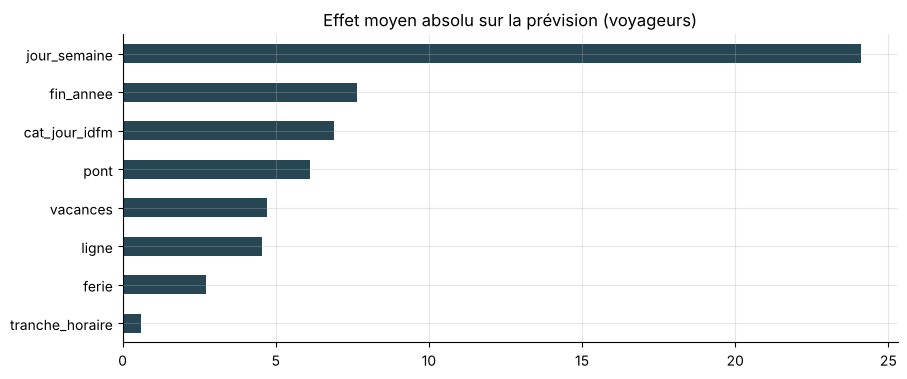

In [10]:
contrib = modele.boosters[0.5].predict(modele.matrice(pred), pred_contrib=True)[:, :-1]
importance = pd.Series(np.abs(contrib * pred["niveau_habituel"].to_numpy()[:, None]).mean(axis=0),
                       index=cfg.variables).sort_values()
importance.plot.barh(title="Effet moyen absolu sur la prévision (voyageurs)", color="#264653")
plt.show()

## 7. Exemple : une prévision expliquée

La prévision publiée (`gold/previsions.parquet`) se lit comme une addition : niveau habituel, écart
moyen du modèle, puis l'effet de chaque variable. C'est exactement ce qu'affichent D4 et l'API.

In [11]:
from comptage_train.api import explication

prev = pd.read_parquet(DATA / "gold" / "previsions.parquet")
ex = prev[(prev["code_gare"] == "87271031") & (prev["tranche_horaire"] == "De 6h à 10h")].iloc[0]
print(ex["nom_gare"], ex["ligne"], ex["date"], ex["tranche_horaire"], "->", ex["niveau"])
print(f"P10-P90 : {ex['p10']} - {ex['p90']}")
print(explication(ex))
pd.DataFrame(list(ex["contributions"])).sort_values("effet_voyageurs", key=abs, ascending=False)

PARIS-GARE-DU-NORD B 2026-10-23 00:00:00 De 6h à 10h -> MOYENNE
P10-P90 : 12707 - 26993
niveau habituel 21209 voy. | jour de la semaine (5) -287 | ligne (B) +231 | fêtes de fin d'année (0) +110 | autres effets -47 = 21216 voyageurs prévus


,variable,valeur,effet_voyageurs
2,jour_semaine,5,-287.4
1,ligne,B,231.1
7,fin_annee,0,110.4
5,vacances,1,-89.2
6,pont,0,45.8
3,cat_jour_idfm,JOVS,37.0
4,ferie,0,-26.7
0,tranche_horaire,De 6h à 10h,-5.8


In [12]:
prev.groupby("niveau").size().rename("prévisions").to_frame().assign(part=lambda d: (d["prévisions"] / d["prévisions"].sum()).round(3))

,prévisions,part
niveau,,
FAIBLE,6511,0.500
FORTE,1655,0.127
MOYENNE,4854,0.373


## 8. Limites connues

* **Pas de capacité des trains en Open Data** : le niveau FAIBLE / MOYENNE / FORTE compare
  l'intensité prévue (voyageurs par heure) à l'historique de la même gare et ligne (médiane et
  85e centile), pas à un taux de remplissage.
* **Retard IDFM** : on prévoit J+1 à J+7 à partir d'un historique qui s'arrête environ 4 mois plus
  tôt. Le niveau habituel suit donc avec retard une tendance de fond (hausse de fréquentation,
  travaux longs).
* **Événements non calendaires** (grèves, incidents, concerts, travaux) : invisibles pour le modèle,
  ce sont les jours où il perd (§3). Une source Open Data d'information voyageurs ou de travaux
  planifiés serait la prochaine variable à évaluer.
* **Météo** : écartée (§4), à réévaluer avec deux hivers d'historique.
* **Gares** : seules les gares × lignes étalonnées à l'étape 3 sont prévues.